# Polynomial Regression — Hands-on Demo


## Setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)


## Section 1 — Why a Straight Line Isn't Always Enough


We load the Auto MPG dataset directly (seaborn fetches it for us) and fit a plain Linear Regression on `horsepower -> mpg`.

In [ ]:
# seaborn ships this dataset and fetches it automatically
df = sns.load_dataset("mpg").dropna(subset=["horsepower", "mpg"]).reset_index(drop=True)

print(df.shape)
df[["horsepower", "mpg"]].head()


(392, 9)


,horsepower,mpg
0,130.0,18.0
1,165.0,15.0
2,150.0,18.0
3,150.0,16.0
4,140.0,17.0


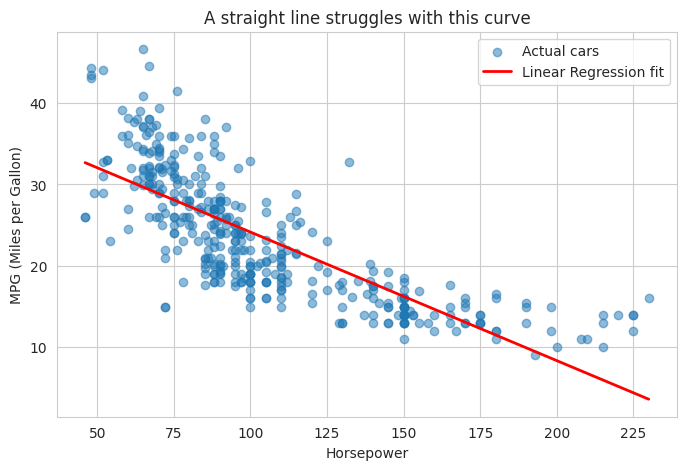

In [ ]:
X = df[["horsepower"]].values
y = df["mpg"].values

lin_model = LinearRegression().fit(X, y)

x_line = np.linspace(X.min(), X.max(), 200).reshape(-1, 1)
y_line_linear = lin_model.predict(x_line)

plt.scatter(X, y, alpha=0.5, label="Actual cars")
plt.plot(x_line, y_line_linear, color="red", linewidth=2, label="Linear Regression fit")
plt.xlabel("Horsepower")
plt.ylabel("MPG (Miles per Gallon)")
plt.title("A straight line struggles with this curve")
plt.legend()
plt.show()


## Section 2 — The Mathematical Blueprint


`PolynomialFeatures` turns a single raw feature `x` into `x, x^2, x^3, ...`. Linear Regression then just fits a straight line **in this new, expanded feature space** — which curves back when plotted against the original `x`.

In [ ]:
# Tiny example so you can literally see what PolynomialFeatures does
sample = np.array([[2], [3], [4]])

poly_demo = PolynomialFeatures(degree=3, include_bias=False)
sample_poly = poly_demo.fit_transform(sample)

pd.DataFrame(sample_poly, columns=poly_demo.get_feature_names_out(["x"]))


,x,x^2,x^3
0,2.0,4.0,8.0
1,3.0,9.0,27.0
2,4.0,16.0,64.0


## Section 3 — Fitting Polynomial Regression

We chain `PolynomialFeatures` and `LinearRegression` with a `Pipeline` so both steps happen together, cleanly.

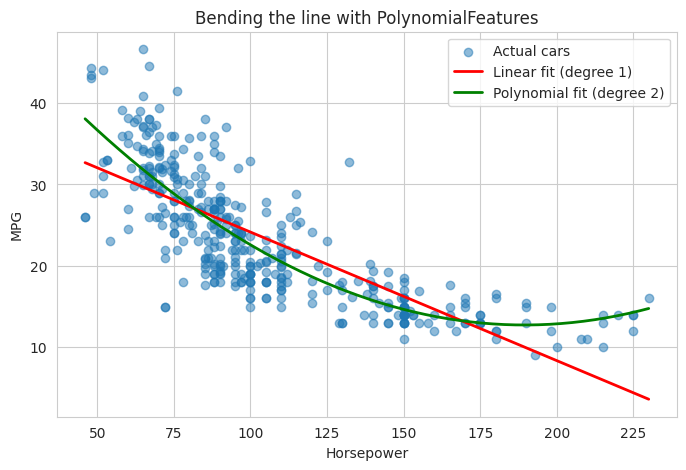

In [ ]:
poly_model = Pipeline([
    ("poly_features", PolynomialFeatures(degree=2, include_bias=False)),
    ("linear_reg", LinearRegression())
])
poly_model.fit(X, y)

y_line_poly = poly_model.predict(x_line)

plt.scatter(X, y, alpha=0.5, label="Actual cars")
plt.plot(x_line, y_line_linear, color="red", linewidth=2, label="Linear fit (degree 1)")
plt.plot(x_line, y_line_poly, color="green", linewidth=2, label="Polynomial fit (degree 2)")
plt.xlabel("Horsepower")
plt.ylabel("MPG")
plt.title("Bending the line with PolynomialFeatures")
plt.legend()
plt.show()


## Section 4 — Degree Is the Model's Flexibility Knob


As degree goes up, the curve gets more flexible — until it starts chasing noise instead of the trend (overfitting).

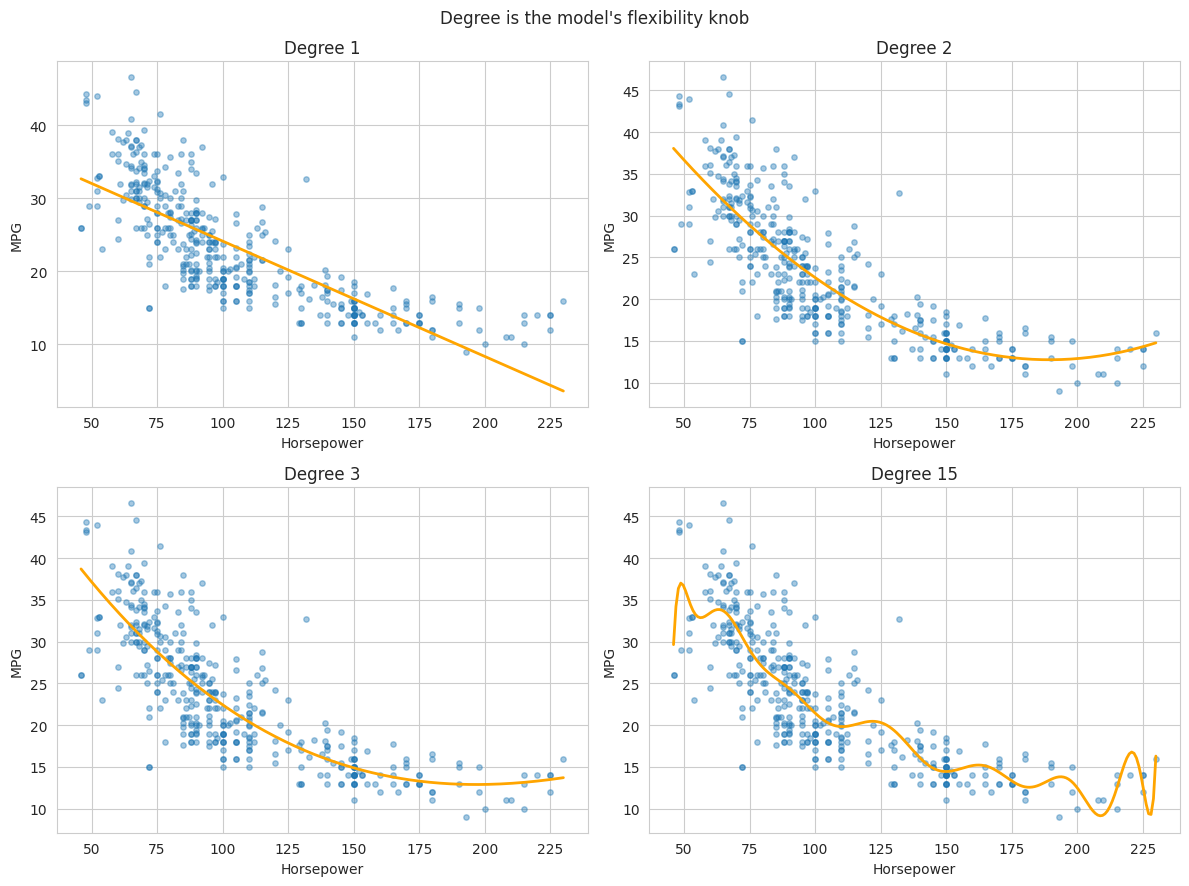

In [ ]:
degrees_to_show = [1, 2, 3, 15]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.ravel()

for ax, d in zip(axes, degrees_to_show):
    model = Pipeline([
        ("poly_features", PolynomialFeatures(degree=d, include_bias=False)),
        ("scaler", StandardScaler()),
        ("linear_reg", LinearRegression())
    ])
    model.fit(X, y)
    y_pred_line = model.predict(x_line)

    ax.scatter(X, y, alpha=0.4, s=15)
    ax.plot(x_line, y_pred_line, color="orange", linewidth=2)
    ax.set_title(f"Degree {d}")
    ax.set_xlabel("Horsepower")
    ax.set_ylabel("MPG")

plt.suptitle("Degree is the model's flexibility knob")
plt.tight_layout()
plt.show()


## Section 5 — Training Error Alone Can't Tell You the Right Degree


We split the data into train and validation sets, then track both errors as degree increases.

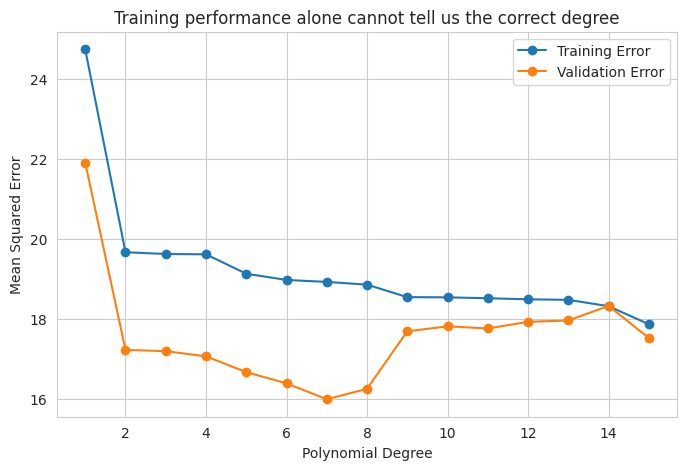

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

train_errors = []
val_errors = []
degree_range = range(1, 16)

for d in degree_range:
    model = Pipeline([
        ("poly_features", PolynomialFeatures(degree=d, include_bias=False)),
        ("scaler", StandardScaler()),
        ("linear_reg", LinearRegression())
    ])
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_test)

    train_errors.append(mean_squared_error(y_train, train_pred))
    val_errors.append(mean_squared_error(y_test, val_pred))

plt.plot(list(degree_range), train_errors, marker="o", label="Training Error")
plt.plot(list(degree_range), val_errors, marker="o", label="Validation Error")
plt.xlabel("Polynomial Degree")
plt.ylabel("Mean Squared Error")
plt.title("Training performance alone cannot tell us the correct degree")
plt.legend()
plt.show()


## Section 6 — Multi-Feature Expansion Causes Feature Explosion


With more than one raw feature, `PolynomialFeatures` also creates **interaction terms** (e.g. `horsepower * weight`), so the feature count grows fast.

In [ ]:
multi_features = df[["horsepower", "weight", "displacement"]].dropna().values

feature_counts = []
for d in range(1, 6):
    poly = PolynomialFeatures(degree=d, include_bias=False)
    poly.fit(multi_features)
    feature_counts.append(len(poly.get_feature_names_out()))

pd.DataFrame({"degree": list(range(1, 6)), "num_generated_features": feature_counts})


,degree,num_generated_features
0,1,3
1,2,9
2,3,19
3,4,34
4,5,55


## Section 7 — Why Scaling Matters
*"High-degree terms destabilize the model numerically"*

`x`, `x^2`, `x^3` live on very different scales. `StandardScaler` after `PolynomialFeatures` keeps the model numerically stable — this is why the pipelines above already included it for higher degrees.

> If you want to constrain the model further, swap `LinearRegression()` for `Ridge(alpha=...)` or `Lasso(alpha=...)` inside the same pipeline — exactly as covered in the Linear Regression video, so it's not repeated here.

In [ ]:
# See the scale explosion for yourself
sample_hp = np.array([[100.0]])
poly3 = PolynomialFeatures(degree=3, include_bias=False)
print("x, x^2, x^3 for horsepower = 100:", poly3.fit_transform(sample_hp))


x, x^2, x^3 for horsepower = 100: [[1.e+02 1.e+04 1.e+06]]


## Section 8 — The Extrapolation Trap


We train only on lower-horsepower cars, then ask the model to predict on horsepower values it never saw. Watch how unstable the curve gets outside the training range.

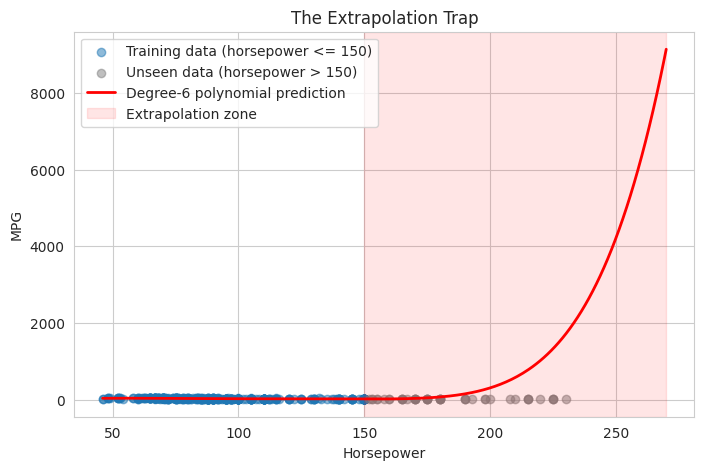

In [ ]:
mask = df["horsepower"] <= 150
X_sub = df.loc[mask, ["horsepower"]].values
y_sub = df.loc[mask, "mpg"].values

extrap_model = Pipeline([
    ("poly_features", PolynomialFeatures(degree=6, include_bias=False)),
    ("scaler", StandardScaler()),
    ("linear_reg", LinearRegression())
])
extrap_model.fit(X_sub, y_sub)

x_wide = np.linspace(df["horsepower"].min(), df["horsepower"].max() + 40, 300).reshape(-1, 1)
y_wide_pred = extrap_model.predict(x_wide)

plt.scatter(X_sub, y_sub, alpha=0.5, label="Training data (horsepower <= 150)")
plt.scatter(df.loc[~mask, "horsepower"], df.loc[~mask, "mpg"],
            alpha=0.5, color="gray", label="Unseen data (horsepower > 150)")
plt.plot(x_wide, y_wide_pred, color="red", linewidth=2, label="Degree-6 polynomial prediction")
plt.axvspan(150, x_wide.max(), color="red", alpha=0.1, label="Extrapolation zone")
plt.xlabel("Horsepower")
plt.ylabel("MPG")
plt.title("The Extrapolation Trap")
plt.legend()
plt.show()


##Key Takeaways

- Polynomial Regression = feature transformation (`PolynomialFeatures`) + Linear Regression — nothing more.
- Degree controls flexibility: too low underfits, too high overfits.
- Training error alone never tells you the right degree — always check validation error.
- More raw features + higher degree = feature explosion (interaction terms included).
- Always scale after expanding features, especially before regularization.
- Never trust a polynomial model's predictions outside the range of the training data.